Publication adaptation: workspace labels and runtime paths have been renamed. Saved scientific results and embedded image bytes are retained from the recorded run; this source notebook has not been recomputed after that adaptation. Printed historical checksums describe that recorded run. Current released-file checksums are in the publication source map.

# Resolved-family Day-7 HSPC programs

## Context and methods

Retrospective molecular characterization of the fixed WT metaclones, not prediction of mutation responses. The input cohort is the shared resolved lineage-family registry. Every Day-7 WT HSPC is eligible whether or not a sister family is subsequently recovered in a mutant arm. HSC/MPP source states are pooled as HSPCs. Replicate and sex are not modeled or interpreted, following the data owner's instruction; the seven previously excluded sex-associated genes remain excluded from feature selection. Feature eligibility is repaired to the source's RNA block before excluding mitochondrial and sex-associated genes. This excludes all lineage barcodes/reporters, rather than only Sapphire features. The source log1p values are inverted to normalized noninteger abundances, rescaled to 10,000 using the complete RNA block, and log1p-transformed before gene exclusion and HVG selection. No raw integer counts are reconstructed. The original recipe and the non-promoted first attempt are retained for audit; RNA feature exclusion without RNA renormalization is preserved as a sensitivity.

The rank is **locked at eight**, not claimed to be optimal. One ordinary NMF fit reuses the original Seurat-style 2,000-HVG selection, NNDSVD initialization, seed zero, coordinate-descent solver and tolerance 1e-5 after the RNA eligibility and normalization repair; no rank, seed or significance search is performed. The iteration cap is raised from 1,200 to 5,000 solely because the normalized RNA fit reached the inherited cap without convergence. Spectra are matched to the established P1–P8 identifiers by a one-to-one Hungarian assignment maximizing cosine similarity on the union gene space. Matched cosines below 0.80 flag weakened identity correspondence for interpretation, not model selection. The original model containing a reporter feature is never used as a projection fallback. This is plain NMF, not consensus NMF.

Cells are averaged within each resolved family, then families equally within each metaclone. Program fractions are relative to the sum of the eight NMF coefficients. Resampling intervals are pointwise 95% percentile intervals from 2,000 seeded family resamples within each fixed metaclone, conditional on the fitted spectra, fixed grouping and observed experiment; they are not between-animal uncertainty, tests of metaclone-specific enrichment, or causal effects. Leave-one-family-out changes and cell-weighted profiles are retained as sensitivities.

Overrepresentation analysis uses the top 100 loading genes and top 100 specificity-weighted genes for each program against the fitted HVG background. All terms with 5–500 background genes in each of six local GMT libraries enter one pooled BH family, including zero- and one-hit terms. Display filtering happens only after correction. Gene-set tests annotate programs, not metaclones.

## Environment

Existing environment **chronoclone**, `/path/to/ChronoClone/.runtime/chronoclone`, kernel **chronoclone**. Reused without installation or mutation. Versions and exact execution command are printed in the next cell. Run the builder only to reconstruct the notebook source; execute the notebook for all results.


In [1]:

from pathlib import Path
import sys, json, platform, hashlib, importlib.metadata as metadata, warnings, shutil
import numpy as np
import pandas as pd
import anndata as ad
import scanpy as sc
import matplotlib.pyplot as plt
from scipy.optimize import linear_sum_assignment
from scipy.stats import hypergeom, spearmanr
from sklearn.decomposition import NMF, non_negative_factorization
from sklearn.exceptions import ConvergenceWarning
from statsmodels.stats.multitest import multipletests
from IPython.display import display
ROOT = Path('/path/to/ChronoClone')
O = ROOT/'analysis_workspace/singh/singh_reference_response_20260911/programs'
REGISTRY = O.parent/'dynamics/tables/cells_resolved.csv'
DATA = ROOT/'reference_workspace/data/adata_valid_palantir_20260626.h5ad'
OLD = ROOT/'reference_workspace/Figure/metaclone_day7_programs_20260909'
GMT = ROOT/'reference_workspace/Figure/singh_npm1c_focus_20260902/objects/gmt'
for name in ['tables','objects','panels','reports']: (O/name).mkdir(parents=True, exist_ok=True)
runner = ROOT/'analysis_workspace/manuscript/chronoclone_panel_revision_20260910/execute_notebook.py'
env = {'name':'chronoclone','manager':'existing Conda-compatible installation; no mutation',
       'path':str(Path(sys.executable).parent.parent),'kernel':'chronoclone',
       'Python':platform.python_version(),
       'versions':{p:metadata.version(p) for p in ['numpy','pandas','scanpy','anndata','scikit-learn','scipy','statsmodels','matplotlib','nbformat']},
       'execution_command':f'{sys.executable} {runner} {O/"0002_rna_normalized_day7_programs.ipynb"}'}
assert env['path']=='/path/to/ChronoClone/.runtime/chronoclone'
(O/'reports/environment.json').write_text(json.dumps(env,indent=2))
display(env)
SOURCE_FILES = [REGISTRY, DATA, OLD/'objects/nmf_day7_spectra.npz', OLD/'tables/nmf_day7_usage.csv', OLD/'scripts/nmf_day7.py', *sorted(GMT.glob('*.gmt'))]
SOURCE_FILES += [ROOT/'reference_workspace/notebooks/export_mast_bundle.py',ROOT/'reference_workspace/Figure/singh_d7_gene_programs_20260902/notebooks/gp_core.py']
sensitivity_source=O/'snapshots/rna_features_original_normalization_sensitivity_20260911/tables/metaclone_mean_usage.csv'
if sensitivity_source.exists():SOURCE_FILES.append(sensitivity_source)
def digest(path):
    h=hashlib.sha256()
    with open(path,'rb') as handle:
        for block in iter(lambda: handle.read(1024*1024),b''): h.update(block)
    return h.hexdigest()
manifest=pd.DataFrame([{'path':str(p.relative_to(ROOT)),'sha256':digest(p),'bytes':p.stat().st_size} for p in SOURCE_FILES])
manifest.to_csv(O/'reports/source_manifest.csv',index=False)
snapshot=O/'snapshots/nonpromoted_reporter_feature_attempt_20260911'
if not snapshot.exists():
    snapshot.mkdir(parents=True)
    for folder in ['tables','objects','panels','reports']:
        if (O/folder).exists():shutil.copytree(O/folder,snapshot/folder)
    (snapshot/'REASON.txt').write_text('Non-promoted initial resolved-cohort fit retained GFP-47 because the inherited recipe excluded only Sapphire barcodes. Superseded by explicit RNA-block eligibility before HVG selection. These artifacts are not manuscript evidence. This snapshot preserves existing attempt outputs, including diagnostic reports added after that attempt.\n')
plt.rcParams.update({'svg.fonttype':'none','font.family':'Arial','font.size':14,
                     'axes.labelsize':16,'xtick.labelsize':13,'ytick.labelsize':13,
                     'axes.spines.top':False,'axes.spines.right':False,'figure.dpi':110})
PNS=[f'P{i}' for i in range(1,9)]
RENORMALIZE_RNA=True
rna_snapshot=O/'snapshots/rna_features_original_normalization_sensitivity_20260911'
if not rna_snapshot.exists():
    rna_snapshot.mkdir(parents=True)
    for folder in ['tables','objects','panels','reports']:
        if (O/folder).exists():shutil.copytree(O/folder,rna_snapshot/folder)
    old_notebook=O/'0001_resolved_day7_programs.ipynb'
    if old_notebook.exists():shutil.move(str(old_notebook),str(rna_snapshot/old_notebook.name))
    (rna_snapshot/'REASON.txt').write_text('Sensitivity: resolved cohort and RNA-block feature eligibility, retaining original full-feature-total log1p normalization. Primary analysis additionally renormalizes on the complete RNA block before gene exclusion and HVG selection. Preserved executed notebook documents exact sensitivity calculation. Do not rerun this historical notebook into the current primary output directory.\n')


{'name': 'chronoclone',
 'manager': 'existing Conda-compatible installation; no mutation',
 'path': '/path/to/ChronoClone/.runtime/chronoclone',
 'kernel': 'chronoclone',
 'Python': '3.11.15',
 'versions': {'numpy': '2.4.6',
  'pandas': '2.3.3',
  'scanpy': '1.11.5',
  'anndata': '0.12.18',
  'scikit-learn': '1.9.0',
  'scipy': '1.17.1',
  'statsmodels': '0.14.6',
  'matplotlib': '3.11.0',
  'nbformat': '5.10.4'},
 'execution_command': '/path/to/ChronoClone/.runtime/chronoclone/bin/python /path/to/ChronoClone/analysis_workspace/manuscript/chronoclone_panel_revision_20260910/execute_notebook.py /path/to/ChronoClone/analysis_workspace/singh/singh_reference_response_20260911/programs/0002_rna_normalized_day7_programs.ipynb'}

## Data and cohort reconciliation

The shared dynamics registry controls molecular eligibility and family identity. The audit reports removed observations, namespace agreement, and metaclone support before expression modeling. The two historical source HSPC labels are not analyzed as different compartments.


In [2]:

registry=pd.read_csv(REGISTRY,index_col='cell_id',dtype={'clone':str})
cohort=registry.loc[(registry.day=='D7') & (registry.arm=='WT') & (registry.ct=='HSPC'),['clone','mc']].copy()
cohort.mc=cohort.mc.astype(int)
assert cohort.index.is_unique and cohort.clone.notna().all()
assert not cohort.clone.isin(['nan','None','-1','']).any()
assert cohort.groupby('clone').mc.nunique().max()==1
backed=ad.read_h5ad(DATA,backed='r')
assert cohort.index.isin(backed.obs_names).all()
source_obs=backed.obs.loc[cohort.index]
assert (source_obs.clone_id_rebuild.astype(str).to_numpy()==cohort.clone.to_numpy()).all()
assert (source_obs.metaclone.astype(str).str.extract(r'(\d+)')[0].astype(int).to_numpy()==cohort.mc.to_numpy()).all()
A=backed[cohort.index,:].to_memory()
source_uns_keys=list(backed.uns.keys())
backed.file.close()
old_usage=pd.read_csv(OLD/'tables/nmf_day7_usage.csv',index_col=0)
removed=old_usage.loc[~old_usage.index.isin(cohort.index)]
removed.to_csv(O/'tables/excluded_unresolved_day7_cells.csv',index_label='cell_id')
assert len(cohort)==2713 and cohort.clone.nunique()==1514 and len(removed)==6
assert set(A.obs.condition.astype(str))=={'WT'}
assert set(A.obs.cell_type.astype(str)) <= {'HSC','MPP'}
cohort.to_csv(O/'tables/day7_resolved_family_registry.csv',index_label='cell_id')
depth=cohort.groupby('mc').agg(n_cells=('clone','size'),n_families=('clone','nunique'))
depth.to_csv(O/'tables/metaclone_depth.csv')
checks={'resolved_cells':len(cohort),'resolved_families':int(cohort.clone.nunique()),
        'removed_cells':len(removed),'old_cells':len(old_usage),'old_original_ids':int(old_usage.clone_id.nunique()),
        'shared_registry_exact_match':True,'source_uns_keys':source_uns_keys}
(O/'reports/cohort_checks.json').write_text(json.dumps(checks,indent=2))
display(checks); display(depth)


{'resolved_cells': 2713,
 'resolved_families': 1514,
 'removed_cells': 6,
 'old_cells': 2719,
 'old_original_ids': 1516,
 'shared_registry_exact_match': True,
 'source_uns_keys': ['cellType_colors',
  'cell_type_2_colors',
  'cell_type_colors',
  'diffmap_evals',
  'iroot',
  'log1p',
  'neighbors',
  'palantir_fates_colors']}

,n_cells,n_families
mc,,
0,935,596
1,192,71
2,58,27
3,206,104
4,44,18
5,41,17
6,73,36
7,400,251
9,47,24


## Fixed-rank refit and identity alignment

The original rank is retained after explicit RNA-feature and RNA-total-normalization corrections. The only cohort change is removal of unresolved family IDs. Cosine matching is a label-alignment diagnostic, not evidence of an association with outcomes.


In [3]:

SEX=['Xist','Tsix','Ddx3y','Eif2s3y','Kdm5d','Usp9y','Uty']
vn=pd.Index(A.var_names)
rna_boundary=next(i for i,g in enumerate(vn) if g.startswith(('Sapphire1-','Sapphire2-','GFP-','Cre-','Flp-')))
assert rna_boundary==20994
rna_matrix=A[:,:rna_boundary].X.copy().astype(np.float64)
rna_matrix.data=np.expm1(rna_matrix.data)
rna_total=np.asarray(rna_matrix.sum(axis=1)).ravel()
all_feature_matrix=A.X.copy().astype(np.float64)
all_feature_matrix.data=np.expm1(all_feature_matrix.data)
all_feature_total=np.asarray(all_feature_matrix.sum(axis=1)).ravel()
normalization_report={'source_matrix':'AnnData.X, log1p expression normalized on all original features',
                      'primary_transform':'expm1 on complete RNA block; RNA sum scaled to 10000; log1p before gene exclusion and HVG selection',
                      'first_reporter_feature_index':rna_boundary,
                      'rna_expm1_total_min':float(rna_total.min()),
                      'rna_expm1_total_median':float(np.median(rna_total)),
                      'rna_expm1_total_max':float(rna_total.max()),
                      'all_rna_expm1_totals_close_10000_rtol_1e5':bool(np.allclose(rna_total,10000,rtol=1e-5)),
                      'all_feature_expm1_total_min':float(all_feature_total.min()),
                      'all_feature_expm1_total_median':float(np.median(all_feature_total)),
                      'all_feature_expm1_total_max':float(all_feature_total.max()),
                      'all_full_expm1_totals_close_10000_rtol_1e5':bool(np.allclose(all_feature_total,10000,rtol=1e-5)),
                      'rna_fraction_min':float((rna_total/all_feature_total).min()),
                      'rna_fraction_median':float(np.median(rna_total/all_feature_total)),
                      'rna_fraction_max':float((rna_total/all_feature_total).max()),
                      'nonzero_X_min':float(A.X.data.min()),'nonzero_X_max':float(A.X.data.max())}
(O/'reports/input_normalization_checks.json').write_text(json.dumps(normalization_report,indent=2))
display(normalization_report)
# Historical recipe and excluded feature are audited, never used for the promoted refit.
prior=np.load(OLD/'objects/nmf_day7_spectra.npz',allow_pickle=True)
old_H=np.asarray(prior['H'],dtype=float);old_genes=np.asarray(prior['genes'],dtype=str)
original_nonrna=sorted(set(old_genes)-set(vn[:rna_boundary]))
feature_audit=[]
for feature in original_nonrna:
    j=int(np.flatnonzero(old_genes==feature)[0])
    for i,p in enumerate(PNS):feature_audit.append({'feature':feature,'program':p,'loading':old_H[i,j],'fraction_of_program_loading':old_H[i,j]/old_H[i].sum()})
pd.DataFrame(feature_audit).to_csv(O/'reports/original_selected_reporter_feature_loadings.csv',index=False)
pd.Series(vn[rna_boundary:]).str.split('-').str[0].value_counts().rename_axis('prefix').to_csv(O/'reports/non_rna_feature_prefix_counts.csv')
RNA=A[:,:rna_boundary].copy()
if RENORMALIZE_RNA:
    RNA.X=rna_matrix.copy()
    sc.pp.normalize_total(RNA,target_sum=10000)
    RNA.X.data=np.log1p(RNA.X.data)
    RNA.uns['log1p']={'base':None}
    check_rna=RNA.X.copy();check_rna.data=np.expm1(check_rna.data)
    assert np.allclose(np.asarray(check_rna.sum(axis=1)).ravel(),10000,rtol=1e-8)
rna_names=pd.Index(RNA.var_names)
keep=~(rna_names.str.startswith('mt-')|rna_names.isin(SEX))
G=RNA[:,np.asarray(keep)].copy()
sc.pp.highly_variable_genes(G,n_top_genes=2000,flavor='seurat')
V=G[:,G.var.highly_variable].copy()
new_genes=np.asarray(V.var_names,dtype=str)
X=np.asarray(V.X.toarray() if hasattr(V.X,'toarray') else V.X,dtype=np.float64)
X[X<0]=0
assert X.shape==(len(cohort),2000) and np.isfinite(X).all()
assert not any(g.startswith(('Sapphire','mt-')) or g in SEX for g in new_genes)
non_rna_hvg=pd.DataFrame({'feature':sorted(set(new_genes)-set(vn[:rna_boundary]))})
non_rna_hvg.to_csv(O/'reports/selected_features_outside_leading_rna_block.csv',index=False)
display(non_rna_hvg)
assert set(new_genes)<=set(vn[:rna_boundary]),'Selected features include a non-RNA barcode/reporter feature.'
model=NMF(n_components=8,init='nndsvd',random_state=0,max_iter=5000,tol=1e-5,solver='cd',beta_loss='frobenius')
with warnings.catch_warnings(record=True) as fit_warnings:
    warnings.simplefilter('always')
    model.fit(X)
    W_new=model.transform(X)
warning_rows=[{'stage':'fixed_rank_seed_tolerance_extended_iteration_cap','category':w.category.__name__,'message':str(w.message)} for w in fit_warnings]
# Preserve the rank, initialization, seed and tolerance; an unconverged candidate is not promoted.
fit_converged=not any(issubclass(w.category,ConvergenceWarning) for w in fit_warnings)
union=np.union1d(old_genes,new_genes)
prior_union=np.zeros((8,len(union)));new_union=np.zeros_like(prior_union)
prior_union[:,np.searchsorted(union,old_genes)]=old_H
new_union[:,np.searchsorted(union,new_genes)]=model.components_
cosine=(prior_union@new_union.T)/(np.linalg.norm(prior_union,axis=1)[:,None]*np.linalg.norm(new_union,axis=1)[None,:])
old_idx,new_idx=linear_sum_assignment(-cosine)
assert np.array_equal(old_idx,np.arange(8))
alignment=pd.DataFrame({'program':PNS,'refit_component':new_idx+1,'cosine_union':cosine[old_idx,new_idx]})
alignment['passes_identity_threshold']=alignment.cosine_union>=.80
use_refit=fit_converged and alignment.passes_identity_threshold.all()
np.savez_compressed(O/'objects/attempted_refit_spectra.npz',H=model.components_,genes=new_genes,alignment=new_idx)
alignment.to_csv(O/'tables/program_identity_alignment.csv',index=False)
assert fit_converged,'RNA-only refit did not converge. No contaminated-model projection fallback.'
H=model.components_[new_idx].copy();W=W_new[:,new_idx];genes=new_genes.copy();matrix=X
route='resolved_cohort_rna_normalized_fixed_rank_refit' if RENORMALIZE_RNA else 'resolved_cohort_rna_only_fixed_rank_refit'
U=W/np.clip(W.sum(axis=1,keepdims=True),1e-12,None)
assert np.allclose(U.sum(axis=1),1) and np.isfinite(U).all()
usage=pd.DataFrame(U,index=cohort.index,columns=PNS).join(cohort)
usage.to_csv(O/'tables/day7_cell_program_usage.csv',index_label='cell_id')
np.savez_compressed(O/'objects/retained_program_spectra.npz',H=H,genes=genes,W=W,cell_ids=cohort.index.to_numpy(dtype=str))
pd.DataFrame(H,index=PNS,columns=genes).to_csv(O/'tables/program_spectra.csv',index_label='program')
alignment.to_csv(O/'tables/program_identity_alignment.csv',index=False)
pd.DataFrame(warning_rows,columns=['stage','category','message']).to_csv(O/'reports/model_warnings.csv',index=False)
fit_report={'retained_route':route,'K':8,'fit_converged':fit_converged,'refit_iterations':int(model.n_iter_),
            'max_iter':5000,'tol':1e-5,'seed':0,'init':'nndsvd','solver':'cd','loss':'frobenius',
            'refit_reconstruction_error':float(model.reconstruction_err_),'retained_reconstruction_error':float(np.linalg.norm(matrix-W@H)),
            'hvg_overlap':len(set(old_genes)&set(new_genes)),'original_n_hvg':len(old_genes),'resolved_n_hvg':len(new_genes),
            'minimum_matched_cosine':float(alignment.cosine_union.min()),'identity_threshold':.8,
            'warning_count':len(warning_rows),'total_features':A.n_vars,'post_exclusion_features':G.n_vars}
fit_report['original_selected_non_rna_features']=original_nonrna
fit_report['retained_selected_non_rna_features']=sorted(set(genes)-set(vn[:rna_boundary]))
(O/'reports/model_fit.json').write_text(json.dumps(fit_report,indent=2))
display(fit_report);display(alignment)


{'source_matrix': 'AnnData.X, log1p expression normalized on all original features',
 'primary_transform': 'expm1 on complete RNA block; RNA sum scaled to 10000; log1p before gene exclusion and HVG selection',
 'first_reporter_feature_index': 20994,
 'rna_expm1_total_min': 9282.373511357271,
 'rna_expm1_total_median': 9920.130541610299,
 'rna_expm1_total_max': 9982.860931763544,
 'all_rna_expm1_totals_close_10000_rtol_1e5': False,
 'all_feature_expm1_total_min': 9999.999999999995,
 'all_feature_expm1_total_median': 10000.0,
 'all_feature_expm1_total_max': 10000.000000000005,
 'all_full_expm1_totals_close_10000_rtol_1e5': True,
 'rna_fraction_min': 0.9282373511357269,
 'rna_fraction_median': 0.9920130541610299,
 'rna_fraction_max': 0.9982860931763547,
 'nonzero_X_min': 0.4388111499769605,
 'nonzero_X_max': 6.003756159144483}

,feature


{'retained_route': 'resolved_cohort_rna_normalized_fixed_rank_refit',
 'K': 8,
 'fit_converged': True,
 'refit_iterations': 1290,
 'max_iter': 5000,
 'tol': 1e-05,
 'seed': 0,
 'init': 'nndsvd',
 'solver': 'cd',
 'loss': 'frobenius',
 'refit_reconstruction_error': 798.009969477377,
 'retained_reconstruction_error': 798.0099695372952,
 'hvg_overlap': 1976,
 'original_n_hvg': 2000,
 'resolved_n_hvg': 2000,
 'minimum_matched_cosine': 0.9605530890059274,
 'identity_threshold': 0.8,
 'warning_count': 0,
 'total_features': 144976,
 'post_exclusion_features': 20974,
 'original_selected_non_rna_features': [np.str_('GFP-47')],
 'retained_selected_non_rna_features': []}

,program,refit_component,cosine_union,passes_identity_threshold
0,P1,1,0.990251,True
1,P2,2,0.985754,True
2,P3,3,0.989764,True
3,P4,4,0.993091,True
4,P5,8,0.991210,True
5,P6,6,0.960553,True
6,P7,7,0.991364,True
7,P8,5,0.982997,True


## Family-balanced profiles and conditional sensitivity

The program fit is label-blind, but metaclones were discovered using the reference data; this is in-sample retrospective characterization. The bootstrap resamples complete family profiles, not individual cells. A cell-weighted estimate and maximal deletion influence expose aggregation sensitivity. No program–mutation-response correlation is fitted here.


In [4]:

family=usage.groupby(['mc','clone'],observed=True)[PNS].mean().reset_index()
assert len(family)==1514 and not family.duplicated(['mc','clone']).any()
family.to_csv(O/'tables/day7_family_program_usage.csv',index=False)
profiles=family.groupby('mc')[PNS].mean()
cell_weighted=usage.groupby('mc')[PNS].mean()
thick=depth.index[depth.n_cells>=32]
zscore=(profiles-profiles.loc[thick].mean())/profiles.loc[thick].std(ddof=0)
profiles.to_csv(O/'tables/metaclone_mean_usage.csv')
zscore.to_csv(O/'tables/metaclone_relative_usage_zscore.csv')
cell_weighted.to_csv(O/'tables/metaclone_cell_weighted_usage_sensitivity.csv')
rng=np.random.default_rng(20260911);B=2000;records=[]
for mc,frame in family.groupby('mc',sort=True):
    arr=frame[PNS].to_numpy();n=len(arr);point=arr.mean(axis=0)
    draws=arr[rng.integers(0,n,size=(B,n))].mean(axis=1)
    lo,hi=np.quantile(draws,[.025,.975],axis=0)
    deleted=(arr.sum(axis=0)-arr)/(n-1)
    for j,p in enumerate(PNS):
        records.append({'mc':int(mc),'program':p,'n_families':n,'mean':point[j],
                        'ci_low':lo[j],'ci_high':hi[j],
                        'max_leave_one_family_change':float(np.abs(deleted[:,j]-point[j]).max()),
                        'cell_weighted_mean':float(cell_weighted.loc[mc,p])})
uncertainty=pd.DataFrame(records)
uncertainty.to_csv(O/'tables/metaclone_program_conditional_intervals.csv',index=False)
old_profiles=old_usage.loc[cohort.index].join(cohort.rename(columns={'clone':'resolved_family'})[['resolved_family']]).groupby(['mc','resolved_family'])[PNS].mean().groupby('mc').mean()
agreement=pd.DataFrame([{'program':p,'metaclone_profile_spearman':spearmanr(old_profiles[p],profiles[p]).statistic,
                        'cell_usage_spearman':spearmanr(old_usage.loc[cohort.index,p],usage[p]).statistic,
                        'largest_absolute_profile_change':float((profiles[p]-old_profiles[p]).abs().max())} for p in PNS])
agreement.to_csv(O/'tables/previous_resolved_profile_agreement.csv',index=False)
normalization_sensitivity=pd.read_csv(rna_snapshot/'tables/metaclone_mean_usage.csv',index_col='mc')
sensitivity_agreement=pd.DataFrame([{'program':p,'profile_spearman':spearmanr(normalization_sensitivity[p],profiles[p]).statistic,
                                     'largest_absolute_profile_change':float((normalization_sensitivity[p]-profiles[p]).abs().max())} for p in PNS])
sensitivity_agreement.to_csv(O/'tables/rna_normalization_sensitivity_profile_agreement.csv',index=False)
display(sensitivity_agreement)
display(agreement)
display(uncertainty.loc[uncertainty.mc.isin([3,7])].round(4))


,program,profile_spearman,largest_absolute_profile_change
0,P1,0.997549,0.004644
1,P2,0.997549,0.001845
2,P3,1.000000,0.001565
3,P4,1.000000,0.001175
4,P5,1.000000,0.001465
5,P6,0.997549,0.001420
6,P7,0.995098,0.001206
7,P8,0.997549,0.005504


,program,metaclone_profile_spearman,cell_usage_spearman,largest_absolute_profile_change
0,P1,0.995098,0.996020,0.010517
1,P2,1.000000,0.998582,0.014715
2,P3,0.995098,0.994746,0.002775
3,P4,0.992647,0.998077,0.005469
4,P5,0.995098,0.998370,0.043656
5,P6,0.990196,0.991451,0.015052
6,P7,0.982843,0.996471,0.032204
7,P8,0.992647,0.995740,0.042889


,mc,program,n_families,mean,ci_low,ci_high,max_leave_one_family_change,cell_weighted_mean
24,3,P1,104,0.2164,0.1971,0.2356,0.0024,0.2086
25,3,P2,104,0.2236,0.1969,0.2527,0.0032,0.2360
26,3,P3,104,0.0927,0.0744,0.1120,0.0023,0.0902
27,3,P4,104,0.1095,0.0894,0.1290,0.0026,0.1086
28,3,P5,104,0.0355,0.0265,0.0442,0.0017,0.0447
29,3,P6,104,0.0812,0.0679,0.0956,0.0018,0.0800
30,3,P7,104,0.1071,0.0864,0.1284,0.0037,0.0954
31,3,P8,104,0.1339,0.1212,0.1478,0.0025,0.1366
56,7,P1,251,0.1237,0.1129,0.1341,0.0013,0.1132
57,7,P2,251,0.1770,0.1572,0.1956,0.0016,0.1936


## Program annotations with a complete enrichment family

The numerical family and displayed labels are calculated below. Broad transcription or RNA-binding labels are not interpreted as proof of a specific regulator or lineage fate; the underlying specific genes are retained alongside the terms.


In [5]:

Hn=H/H.sum(axis=1,keepdims=True)
specific=Hn*(Hn/np.maximum(Hn.sum(axis=0,keepdims=True),1e-300))
queries={('top_loading',p):genes[np.argsort(-H[i])[:100]].tolist() for i,p in enumerate(PNS)}
queries.update({('specific',p):genes[np.argsort(-specific[i])[:100]].tolist() for i,p in enumerate(PNS)})
background={g.upper() for g in genes}
libraries={}
for path in sorted(GMT.glob('*.gmt')):
    terms={}
    with path.open() as handle:
        for line in handle:
            fields=line.rstrip('\n').split('\t')
            if len(fields)>=3:
                members={g.split(',')[0].strip().upper() for g in fields[2:] if g.strip()}
                if members:terms[fields[0]]=members
    libraries[path.stem]=terms
assert len(libraries)==6
terms=[]
for lib,sets in libraries.items():
    for term,members in sets.items():
        bgset=members&background
        if 5<=len(bgset)<=500: terms.append((lib,term,bgset))
records=[]
for (query,p),members in queries.items():
    queryset={g.upper() for g in members}&background;N=len(queryset);M=len(background)
    for lib,term,bgset in terms:
        n=len(bgset);hits=queryset&bgset;k=len(hits)
        records.append({'query':query,'program':p,'library':lib,'term':term,'n_background':M,
                        'n_query':N,'n_term_in_background':n,'overlap':k,
                        'fold_enrichment':(k/N)/(n/M),'p':hypergeom.sf(k-1,M,n,N),
                        'overlap_genes':','.join(sorted(hits))})
enrichment=pd.DataFrame(records)
enrichment['q_BH_all_queries_programs_terms']=multipletests(enrichment.p,method='fdr_bh')[1]
assert len(enrichment)==16*len(terms)
assert enrichment.loc[enrichment.overlap==0,'p'].eq(1).all()
enrichment.to_csv(O/'tables/program_enrichment_complete_family.csv',index=False)
eligible_display=enrichment.loc[(enrichment['query']=='specific') & (enrichment.overlap>=2) & enrichment.n_term_in_background.between(15,200)]
labels=eligible_display.loc[eligible_display.groupby('program').p.idxmin()].set_index('program').reindex(PNS)
identities=pd.DataFrame({'program':PNS,
                        'specific_genes': [', '.join(genes[np.argsort(-specific[i])[:12]]) for i in range(8)],
                        'loading_genes':[', '.join(genes[np.argsort(-H[i])[:12]]) for i in range(8)]}).set_index('program')
identities=identities.join(labels[['term','library','overlap','n_term_in_background','q_BH_all_queries_programs_terms']])
identities.to_csv(O/'tables/program_identity_annotations.csv')
pd.DataFrame([{'query':q,'program':p,'rank':i+1,'gene':g} for (q,p),gs in queries.items() for i,g in enumerate(gs)]).to_csv(O/'tables/program_query_genes.csv',index=False)
family_report={'libraries':list(libraries),'eligible_terms_per_query':len(terms),'programs':8,'query_types':2,
               'total_tests':len(enrichment),'q05_tests':int((enrichment.q_BH_all_queries_programs_terms<.05).sum()),
               'displayed_labels_q05':int((identities.q_BH_all_queries_programs_terms<.05).sum()),
               'background_unique_uppercase_genes':len(background),'zero_hit_tests':int((enrichment.overlap==0).sum()),
               'one_hit_tests':int((enrichment.overlap==1).sum())}
(O/'reports/enrichment_family.json').write_text(json.dumps(family_report,indent=2))
display(family_report);display(identities)


{'libraries': ['GO_Biological_Process_2023',
  'GO_Molecular_Function_2023',
  'KEGG_2019_Mouse',
  'MSigDB_Hallmark_2020',
  'Reactome_2022',
  'WikiPathways_2019_Mouse'],
 'eligible_terms_per_query': 1914,
 'programs': 8,
 'query_types': 2,
 'total_tests': 30624,
 'q05_tests': 1204,
 'displayed_labels_q05': 8,
 'background_unique_uppercase_genes': 2000,
 'zero_hit_tests': 14091,
 'one_hit_tests': 8431}

,specific_genes,loading_genes,term,library,overlap,n_term_in_background,q_BH_all_queries_programs_terms
program,,,,,,,
P1,"Adgrl4, Hlf, Gimap6, Mir99ahg, Itsn1, 2610307P...","Adgrl4, Nrxn1, Hlf, Gimap6, 2610307P16Rik, Mir...",Regulation Of Transcription By RNA Polymerase ...,GO_Biological_Process_2023,22,179,2.571628e-03
P2,"Akr1c13, Fdps, S100a4, Nop10, Fabp5, Dbi, Nme1...","Ppia, Nop10, Actb, Ifitm1, Rpl11, Rps15a, Akr1...",RNA Binding (GO:0003723),GO_Molecular_Function_2023,21,64,2.264065e-10
P3,"Ube2c, Nusap1, Cenpf, Hmmr, Cenpa, Prc1, Ccnb1...","Ube2c, Cenpa, Top2a, Nusap1, Birc5, Cenpf, Cdc...",G2-M Checkpoint,MSigDB_Hallmark_2020,32,40,1.007500e-32
P4,"Trib3, Nupr1, Snhg12, Hsd17b1, 5430416N02Rik, ...","Snhg12, Snhg1, Nupr1, 2410006H16Rik, Cebpb, Ga...",Cellular Responses To Stimuli R-HSA-8953897,Reactome_2022,24,66,3.759773e-13
P5,"Tespa1, 4930519L02Rik, 2610307P16Rik, Nkg7, Sl...","Cdk6, 2610307P16Rik, Maml3, Pcdh7, 4930519L02R...",Platelet Degranulation R-HSA-114608,Reactome_2022,7,20,2.071123e-03
P6,"Atad2, Pola1, Hells, Rad51b, Lig1, Rad51ap1, P...","Rad51b, Pola1, Atad2, Top2a, Hells, Pclaf, Lig...",E2F Targets,MSigDB_Hallmark_2020,23,39,3.637599e-18
P7,"Creb5, Myl10, Ankrd37, Tgm2, Bhlhe40, Jdp2, Fy...","Myl10, Creb5, Pgk1, Eno1, Tpi1, Aldoa, Trpc6, ...",Hypoxia,MSigDB_Hallmark_2020,17,53,5.408813e-08
P8,"Ncam2, Med12l, Tgfbr3, C530008M17Rik, Zeb2, Pd...","Med12l, Tgfbr3, Ncam2, C530008M17Rik, Zeb2, Pr...",Neuron Development (GO:0048666),GO_Biological_Process_2023,7,18,1.161757e-03


## Raw figure panels

Each cell below constructs one plot and writes one editable SVG plus a PNG companion. Captions belong to the manuscript, not inside the panels. Relative usage z-scores use the previously declared metaclones with at least 32 observed Day-7 cells for centering/scaling; all metaclones are shown. Family counts label every metaclone. The heatmap does not display significance stars because it is a descriptive program-usage map, not a metaclone differential-expression test.


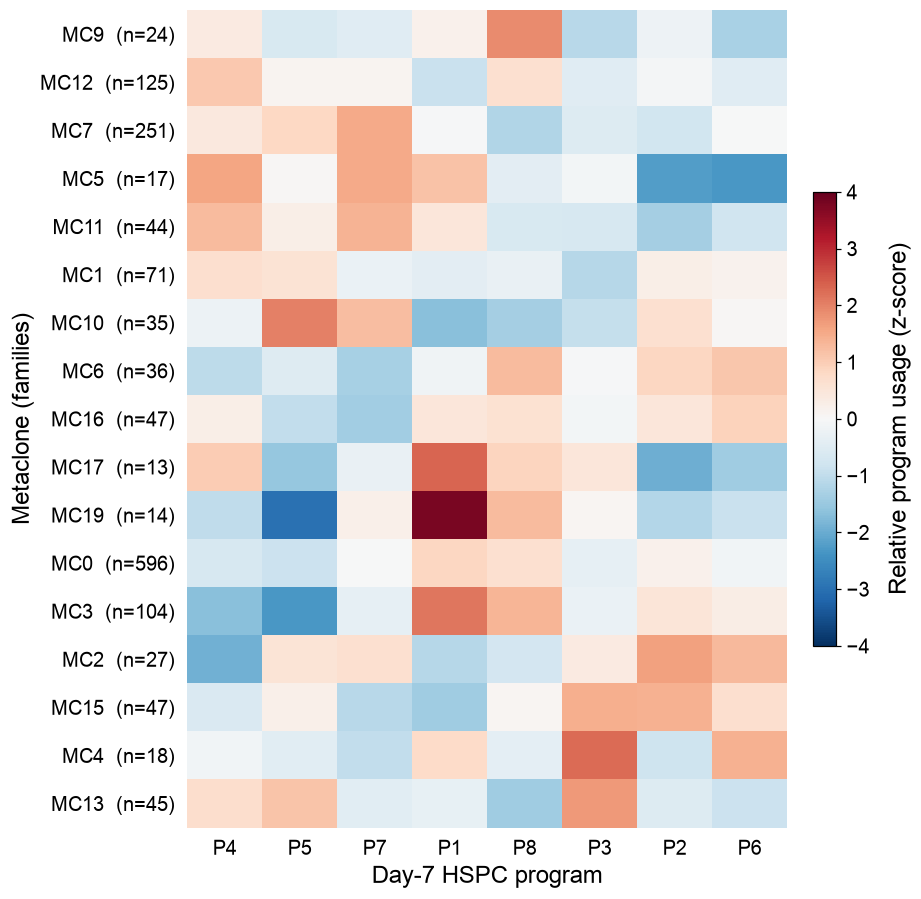

/path/to/ChronoClone/analysis_workspace/singh/singh_reference_response_20260911/programs/panels/06a_day7_metaclone_program_usage.svg


In [6]:

# One plot: all-metaclone relative program usage, equal family weighting.
plot_profiles=usage.groupby(['mc','clone'])[PNS].mean().groupby('mc').mean()
scale_mcs=depth.index[depth.n_cells>=32]
plot_z=(plot_profiles-plot_profiles.loc[scale_mcs].mean())/plot_profiles.loc[scale_mcs].std(ddof=0)
mc_order=[9,12,7,5,11,1,10,6,16,17,19,0,3,2,15,4,13]
program_order=['P4','P5','P7','P1','P8','P3','P2','P6']
plot_data=plot_z.loc[mc_order,program_order]
fig,ax=plt.subplots(figsize=(8.6,8.4))
limit=max(2.,float(np.ceil(np.abs(plot_data.to_numpy()).max()*2)/2))
im=ax.pcolormesh(plot_data.to_numpy(),cmap='RdBu_r',vmin=-limit,vmax=limit,shading='flat',rasterized=False)
ax.invert_yaxis()
ax.set_xticks(np.arange(8)+.5,program_order)
ax.set_yticks(np.arange(len(mc_order))+.5,[f'MC{m}  (n={depth.loc[m,"n_families"]})' for m in mc_order])
ax.set_xlabel('Day-7 HSPC program');ax.set_ylabel('Metaclone (families)')
ax.tick_params(length=0,pad=8)
ax.spines[['top','right','bottom','left']].set_visible(False)
cbar=fig.colorbar(im,ax=ax,fraction=.035,pad=.04)
cbar.solids.set_rasterized(False)
cbar.set_label('Relative program usage (z-score)',labelpad=12)
fig.tight_layout()
stem=O/'panels/06a_day7_metaclone_program_usage'
fig.savefig(stem.with_suffix('.svg'),bbox_inches='tight');fig.savefig(stem.with_suffix('.png'),dpi=220,bbox_inches='tight')
plt.show();print(stem.with_suffix('.svg'))


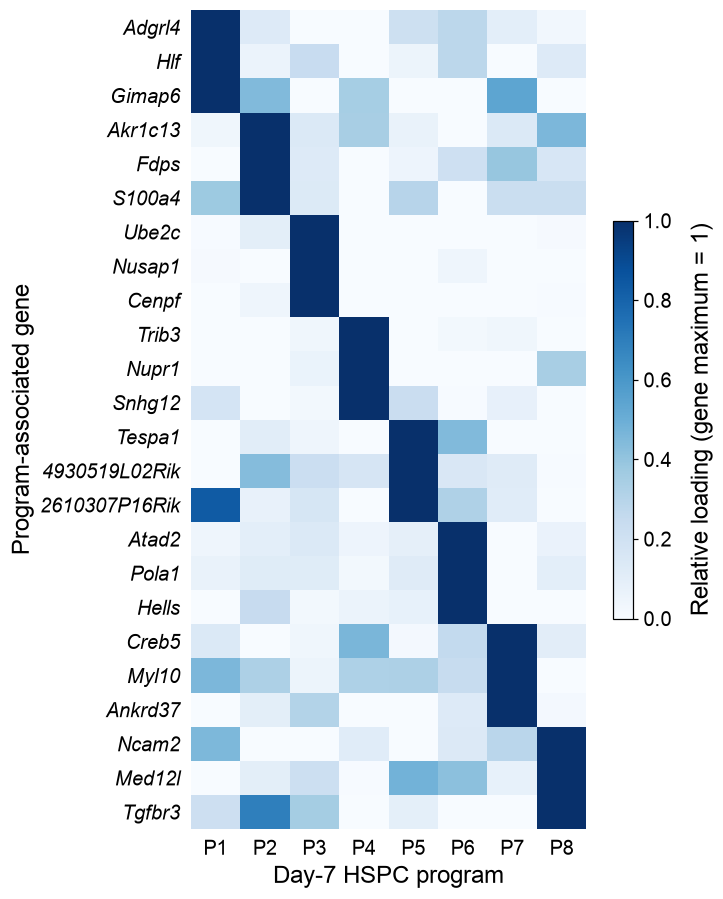

/path/to/ChronoClone/analysis_workspace/singh/singh_reference_response_20260911/programs/panels/06b_day7_program_gene_loadings.svg


In [7]:

# One plot: the three highest-specificity genes per fitted program, unique union.
normalized_loadings=H/H.sum(axis=1,keepdims=True)
specificity=normalized_loadings*(normalized_loadings/np.maximum(normalized_loadings.sum(axis=0,keepdims=True),1e-300))
chosen=[]
for i in range(8):
    for j in np.argsort(-specificity[i])[:3]:
        if int(j) not in chosen:chosen.append(int(j))
load_matrix=normalized_loadings[:,chosen].T
relative_loading=load_matrix/np.maximum(load_matrix.max(axis=1,keepdims=True),1e-300)
fig,ax=plt.subplots(figsize=(6.8,8.4))
im=ax.pcolormesh(relative_loading,cmap='Blues',vmin=0,vmax=1,shading='flat',rasterized=False)
ax.invert_yaxis()
ax.set_xticks(np.arange(8)+.5,PNS)
ax.set_yticks(np.arange(len(chosen))+.5,genes[chosen],fontstyle='italic')
ax.set_xlabel('Day-7 HSPC program');ax.set_ylabel('Program-associated gene')
ax.tick_params(length=0,pad=7)
ax.spines[['top','right','bottom','left']].set_visible(False)
cbar=fig.colorbar(im,ax=ax,fraction=.045,pad=.06)
cbar.solids.set_rasterized(False)
cbar.set_label('Relative loading (gene maximum = 1)',labelpad=12)
fig.tight_layout()
stem=O/'panels/06b_day7_program_gene_loadings'
fig.savefig(stem.with_suffix('.svg'),bbox_inches='tight');fig.savefig(stem.with_suffix('.png'),dpi=220,bbox_inches='tight')
plt.show();print(stem.with_suffix('.svg'))


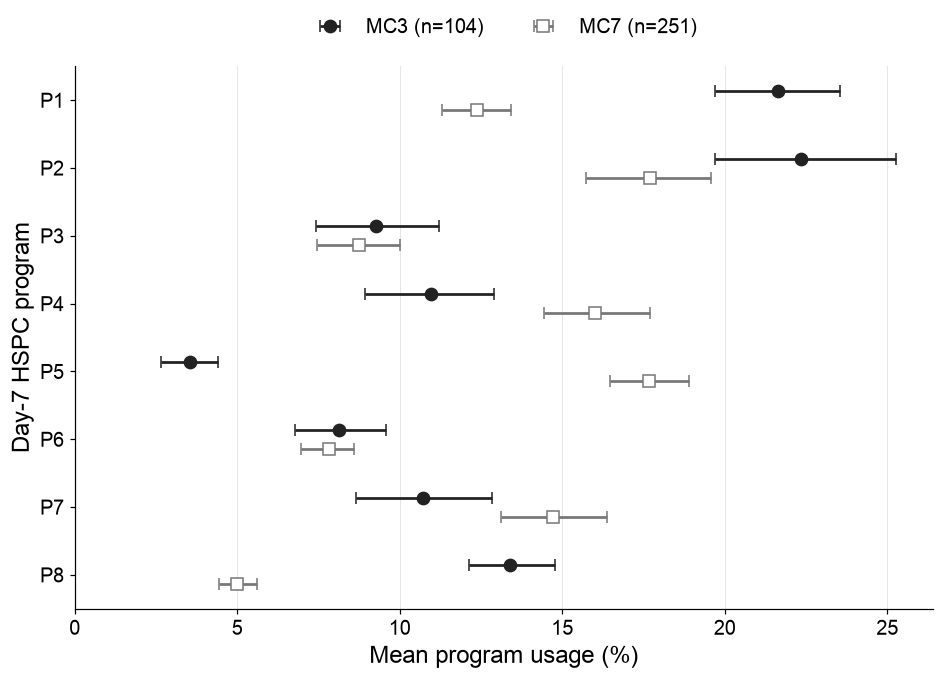

/path/to/ChronoClone/analysis_workspace/singh/singh_reference_response_20260911/programs/panels/06c_day7_mc3_mc7_program_profiles.svg


In [8]:

# One plot: all eight programs in the two reference-dynamics examples, with fixed-fit family intervals.
profile_rows=[];plot_rng=np.random.default_rng(20260911)
for mc,frame in usage.groupby('mc',sort=True):
    family_means=frame.groupby('clone')[PNS].mean().to_numpy();n=len(family_means)
    means=family_means.mean(axis=0)
    resampled=family_means[plot_rng.integers(0,n,size=(2000,n))].mean(axis=1)
    lower,upper=np.quantile(resampled,[.025,.975],axis=0)
    if mc in [3,7]:
        profile_rows.extend([{'mc':mc,'program':p,'mean':means[j],'lower':lower[j],'upper':upper[j],'n_families':n} for j,p in enumerate(PNS)])
plot_table=pd.DataFrame(profile_rows)
plot_table.to_csv(O/'tables/06c_profile_plot_values.csv',index=False)
fig,ax=plt.subplots(figsize=(8.8,6.4))
styles={3:('#222222','o',-.14),7:('#777777','s',.14)}
for mc,(color,marker,offset) in styles.items():
    d=plot_table.loc[plot_table.mc==mc].set_index('program').loc[PNS]
    y=np.arange(8)+offset
    ax.errorbar(100*d['mean'],y,xerr=100*np.vstack([d['mean']-d.lower,d.upper-d['mean']]),
                fmt=marker,color=color,mec=color,mfc=color if mc==3 else 'white',markersize=8,
                elinewidth=1.8,capsize=4,label=f'MC{mc} (n={int(d.n_families.iloc[0])})')
ax.set_yticks(np.arange(8),PNS);ax.invert_yaxis();ax.set_xlim(left=0)
ax.set_xlabel('Mean program usage (%)');ax.set_ylabel('Day-7 HSPC program')
ax.grid(axis='x',color='#e6e6e6',linewidth=.7);ax.set_axisbelow(True)
ax.legend(frameon=False,loc='lower center',bbox_to_anchor=(.5,1.02),ncol=2,fontsize=13)
fig.tight_layout()
stem=O/'panels/06c_day7_mc3_mc7_program_profiles'
fig.savefig(stem.with_suffix('.svg'),bbox_inches='tight');fig.savefig(stem.with_suffix('.png'),dpi=220,bbox_inches='tight')
plt.show();print(stem.with_suffix('.svg'))


## Validation and interpretation boundaries

The following output reports source preservation, family balance, program identities and the profile differences actually observed. Relative usage is a compositional model coefficient, not pathway activation in absolute units. Program enrichment is conditional on the selected HVGs and local library vocabulary. The molecular descriptions do not establish causality, predict response, or provide an independent validation cohort. Independent experimental replication is absent from these conditional family-resampling intervals.


In [9]:

assert usage.index.equals(cohort.index)
assert np.allclose(family[PNS].sum(axis=1),1) and np.allclose(profiles.sum(axis=1),1)
assert len(set(usage.index)&set(removed.index))==0
assert len(enrichment)==8*2*len(terms)
assert enrichment.groupby(['query','program']).size().eq(len(terms)).all()
source_check=manifest.copy()
source_check['sha256_after']=[digest(ROOT/p) for p in source_check.path]
source_check['unchanged']=source_check.sha256==source_check.sha256_after
assert source_check.unchanged.all()
source_check.to_csv(O/'reports/source_integrity_check.csv',index=False)
profile_summary=profiles.loc[[3,7]].T.rename(columns={3:'MC3',7:'MC7'})
profile_summary['MC3_minus_MC7']=profile_summary.MC3-profile_summary.MC7
profile_summary['MC3_z']=zscore.loc[3];profile_summary['MC7_z']=zscore.loc[7]
profile_summary=profile_summary.join(identities[['specific_genes','term','q_BH_all_queries_programs_terms']])
profile_summary.to_csv(O/'tables/retrospective_mc3_mc7_characterization.csv',index_label='program')
display(profile_summary.round(5))
print('Observed program maxima by metaclone:',profiles.idxmax().to_dict())
print('Relative-usage maxima by program:',zscore.idxmax().to_dict())
print('Every source hash unchanged:',bool(source_check.unchanged.all()))
print('Interpretation: descriptive ancestry profiles; no metaclone enrichment significance or mutation-response prediction tested.')
import nbformat, xml.etree.ElementTree as ET
source_nb=nbformat.read(O/'0002_rna_normalized_day7_programs.ipynb',as_version=4)
plot_cells=[c.source for c in source_nb.cells if c.cell_type=='code' and c.source.strip().startswith('# One plot:')]
assert len(plot_cells)==3
assert all(c.count('plt.subplots(')==1 and c.count("with_suffix('.svg')")==2 for c in plot_cells)
assert all('plt.show()' in c and 'stem=O/' in c for c in plot_cells)
svg_checks=[]
for svg in sorted((O/'panels').glob('*.svg')):
    tree=ET.parse(svg);elements=list(tree.iter())
    labels=[e for e in elements if e.tag.endswith('}text')]
    raster=[e for e in elements if e.tag.endswith('}image')]
    svg_checks.append({'panel':svg.stem,'editable_text_elements':len(labels),'raster_images':len(raster)})
    assert len(labels)>0 and len(raster)==0
pd.DataFrame(svg_checks).to_csv(O/'reports/svg_mechanical_checks.csv',index=False)
check_plot=plot_table.merge(uncertainty,on=['mc','program'],suffixes=('_plot','_all'))
assert np.allclose(check_plot.lower,check_plot.ci_low) and np.allclose(check_plot.upper,check_plot.ci_high)
display(pd.DataFrame(svg_checks))
outputs=[p for p in O.rglob('*') if p.is_file() and 'snapshots' not in p.parts and p.suffix in ['.csv','.json','.npz','.svg','.png'] and p.name!='output_manifest.csv']
pd.DataFrame([{'path':str(p.relative_to(O)),'sha256':digest(p),'bytes':p.stat().st_size} for p in sorted(outputs)]).to_csv(O/'reports/output_manifest.csv',index=False)


,MC3,MC7,MC3_minus_MC7,MC3_z,MC7_z,specific_genes,term,q_BH_all_queries_programs_terms
P1,0.21644,0.12371,0.09273,2.13049,-0.05475,"Adgrl4, Hlf, Gimap6, Mir99ahg, Itsn1, 2610307P...",Regulation Of Transcription By RNA Polymerase ...,0.00257
P2,0.22357,0.17701,0.04656,0.52215,-0.75296,"Akr1c13, Fdps, S100a4, Nop10, Fabp5, Dbi, Nme1...",RNA Binding (GO:0003723),0.00000
P3,0.09266,0.08744,0.00522,-0.27187,-0.55677,"Ube2c, Nusap1, Cenpf, Hmmr, Cenpa, Prc1, Ccnb1...",G2-M Checkpoint,0.00000
P4,0.10949,0.16015,-0.05066,-1.67811,0.41698,"Trib3, Nupr1, Snhg12, Hsd17b1, 5430416N02Rik, ...",Cellular Responses To Stimuli R-HSA-8953897,0.00000
P5,0.03553,0.17656,-0.14103,-2.34359,0.83565,"Tespa1, 4930519L02Rik, 2610307P16Rik, Nkg7, Sl...",Platelet Degranulation R-HSA-114608,0.00207
P6,0.08123,0.07808,0.00316,0.28603,-0.01880,"Atad2, Pola1, Hells, Rad51b, Lig1, Rad51ap1, P...",E2F Targets,0.00000
P7,0.10713,0.14700,-0.03988,-0.36695,1.51581,"Creb5, Myl10, Ankrd37, Tgm2, Bhlhe40, Jdp2, Fy...",Hypoxia,0.00000
P8,0.13394,0.05005,0.08389,1.36758,-1.19018,"Ncam2, Med12l, Tgfbr3, C530008M17Rik, Zeb2, Pd...",Neuron Development (GO:0048666),0.00116


Observed program maxima by metaclone: {'P1': 19, 'P2': 2, 'P3': 4, 'P4': 5, 'P5': 10, 'P6': 4, 'P7': 5, 'P8': 9}
Relative-usage maxima by program: {'P1': 19, 'P2': 2, 'P3': 4, 'P4': 5, 'P5': 10, 'P6': 4, 'P7': 5, 'P8': 9}
Every source hash unchanged: True
Interpretation: descriptive ancestry profiles; no metaclone enrichment significance or mutation-response prediction tested.


,panel,editable_text_elements,raster_images
0,06a_day7_metaclone_program_usage,37,0
1,06b_day7_program_gene_loadings,41,0
2,06c_day7_mc3_mc7_program_profiles,18,0
